# 📊 Notebook 01: ASVspoof 2019 LA Data Exploration & Verification

**Project**: AudioShield — Multi-Granularity Temporal Attention for Explainable Audio Deepfake Detection  
**Author**: Abhinay Nama  

---


In [1]:
import os
import sys
from pathlib import Path
import torch
import matplotlib.pyplot as plt
import numpy as np

# Add project root to sys.path
sys.path.append('..')

from src.config import config
from src.data.dataset import ASVspoofDataset
from src.data.dataloader import create_dataloaders, compute_class_weights
from src.data.augmentation import SpecAugment

print(f"PyTorch Version: {torch.__version__}")
print(f"Target Audio Length: {config.audio.target_samples} samples ({config.audio.duration_sec}s @ {config.audio.sample_rate}Hz)")

PyTorch Version: 2.14.0+cu130
Target Audio Length: 64000 samples (4.0s @ 16000Hz)


## 1. Load Dataset & Inspect Statistics

In [2]:
# Real ASVspoof 2019 LA only. Raises FileNotFoundError if data/LA/ is missing (no synthetic fallback).
train_ds = ASVspoofDataset(
    protocol_path=config.paths.train_protocol,
    audio_dir=config.paths.train_audio_dir,
    is_train=True,
    auto_generate_dummy=False,
)

# Compute attack type distribution
attack_counts = {}
for s in train_ds.samples:
    atk = s["attack_type"]
    attack_counts[atk] = attack_counts.get(atk, 0) + 1

print("\n--- Dataset Statistics ---")
print(f"Total Samples: {len(train_ds)}")
for atk, count in sorted(attack_counts.items()):
    print(f"  - Attack/Class '{atk}': {count} samples ({100.0 * count / len(train_ds):.1f}%)")

[Dataset] Loaded 25380 samples from ASVspoof2019.LA.cm.train.trn.txt

--- Dataset Statistics ---
Total Samples: 25380
  - Attack/Class 'A01': 3800 samples (15.0%)
  - Attack/Class 'A02': 3800 samples (15.0%)
  - Attack/Class 'A03': 3800 samples (15.0%)
  - Attack/Class 'A04': 3800 samples (15.0%)
  - Attack/Class 'A05': 3800 samples (15.0%)
  - Attack/Class 'A06': 3800 samples (15.0%)
  - Attack/Class 'bonafide': 2580 samples (10.2%)


## 2. Inspect Waveform Shapes & Batch Iteration

In [3]:
train_loader, dev_loader, eval_loader, class_weights = create_dataloaders(config)

for waveforms, labels, attack_types, utt_ids in train_loader:
    print(f"Batch Waveform Tensor Shape: {waveforms.shape}")
    print(f"Batch Label Tensor Shape: {labels.shape}")
    print(f"Class Weights: {class_weights}")
    break

[Dataset] Loaded 25380 samples from ASVspoof2019.LA.cm.train.trn.txt
[Dataset] Loaded 24844 samples from ASVspoof2019.LA.cm.dev.trl.txt


[Dataset] Loaded 71237 samples from ASVspoof2019.LA.cm.eval.trl.txt
[ClassWeights] Total: 25380 | Spoof (0): 22800 (weight=0.557) | Bonafide (1): 2580 (weight=4.919)


Batch Waveform Tensor Shape: torch.Size([32, 1, 64000])
Batch Label Tensor Shape: torch.Size([32])
Class Weights: tensor([0.5566, 4.9186])


## 3. Waveform & Augmentation Visualizations

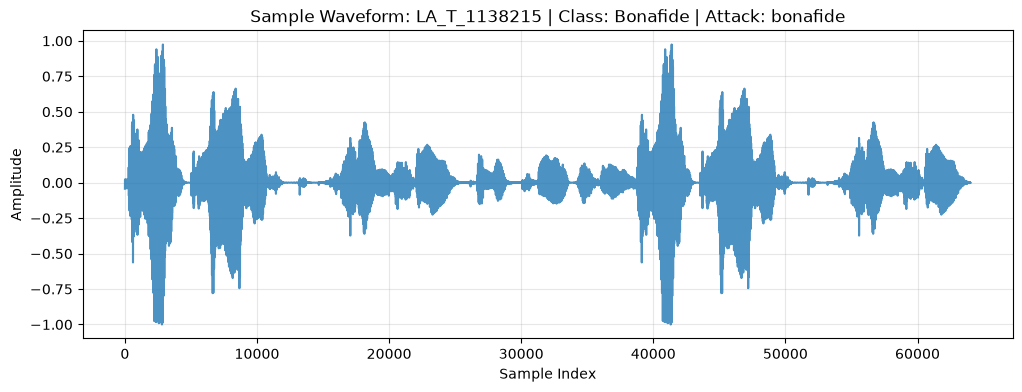

In [4]:
wf, lbl, attack, utt = train_ds[0]

plt.figure(figsize=(12, 4))
plt.plot(wf.squeeze().numpy(), alpha=0.8)
plt.title(f"Sample Waveform: {utt} | Class: {'Bonafide' if lbl.item()==1 else 'Spoof'} | Attack: {attack}")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(True, alpha=0.3)
plt.show()